# 04 · Entrenamiento y ajuste de modelos: Predict Future Sales

**Objetivo:** entrenar 5 familias de modelos con 3 configuraciones cada una (15 modelos), compararlos por **RMSE** en validación y armar el **pipeline completo** (features + modelo ganador) en `models/pipeline_completo.pkl`.

**Esquema de validación (forecasting):** el split es **secuencial, no aleatorio**. Se entrena con los meses 12-26 y se valida con los meses 27-33, que es aproximadamente el 80/20 de la consigna. Se empieza en el mes 12 para que exista el lag 12. Cada mes de validación se predice con los lags reales de los meses anteriores (predicción a un paso), igual que el mes 34 de test se predice con los datos hasta el mes 33.

**Decisiones del usuario:**

- target recortado a [0, 20], y predicciones también recortadas a [0, 20];
- modelos: Ridge, árbol de decisión, random forest, histogram gradient boosting y red neuronal MLP;
- las 15 configuraciones se entrenan con una **muestra aleatoria de 1 millón de filas** de los meses 12-26 y se validan con **todas** las filas de los meses 27-33. El ganador se reentrena después con todos los meses 12-33.

## Configuración

Librerías, configuración y el pipeline de features del notebook 03.

In [1]:
import time

from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
import yaml

from future_sales import dataset as ds
from future_sales.config import MODELS_DIR, PROJ_ROOT, REPORTS_DIR
from future_sales.features import identidad, recortar_prediccion

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titleweight"] = "bold"
PALETA = sns.color_palette("deep", 5)

SEMILLA = 42
TAMANO_MUESTRA = 1_000_000
with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)
pipeline_fe = joblib.load(MODELS_DIR / "pipeline_fe.pkl")
print("Pasos del pipeline de features:",
      [nombre for nombre, _ in pipeline_fe.steps])

2026-11-20 09:00:39.238 | INFO     | future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Proyecto\future-sales


Pasos del pipeline de features: ['mapear', 'generar_lags', 'indicador_faltantes', 'imputar_cero', 'imputar_mediana', 'imputar_categoricas', 'imputar_codigos', 'agrupar_raras', 'one_hot', 'media_target', 'recortar_lags', 'winsorizar', 'log1p', 'eliminar', 'escalar']


## 1. Datos y división temporal

Misma malla y misma división que en el notebook 03. La muestra de entrenamiento se toma al azar **dentro** de los meses 12-26; la validación conserva todas sus filas.

In [2]:
catalogos = ds.cargar_catalogos()
mensual = ds.ventas_mensuales(ds.limpiar_ventas(ds.cargar_ventas()),
                              catalogos["items"])
malla = ds.construir_malla(mensual, range(12, 34))
ENTRADA = ["date_block_num", "shop_id", "item_id"]
TARGET = CFG["TARGET"]

desde, hasta = CFG["MESES_ENTRENAMIENTO"]
es_entrenamiento = malla["date_block_num"].between(desde, hasta)
entrenamiento = malla[es_entrenamiento]
validacion = malla[~es_entrenamiento]
muestra = entrenamiento.sample(TAMANO_MUESTRA, random_state=SEMILLA)

X_muestra, y_muestra = muestra[ENTRADA], muestra[TARGET]
X_val, y_val = validacion[ENTRADA], validacion[TARGET]
print(f"Entrenamiento completo (meses {desde}-{hasta}): "
      f"{len(entrenamiento):,} | muestra: {len(muestra):,}")
print(f"Validación (meses {CFG['MESES_VALIDACION']}): {len(validacion):,}")
print(f"Media del target | muestra: {y_muestra.mean():.4f} | "
      f"validación: {y_val.mean():.4f}")

Entrenamiento completo (meses 12-26): 4,810,730 | muestra: 1,000,000
Validación (meses [27, 33]): 1,614,364
Media del target | muestra: 0.2958 | validación: 0.2617


## 2. Métrica y modelos de referencia

**Métrica:** RMSE sobre el target recortado, con las predicciones también recortadas a [0, 20]. Se reporta además el RMSE normalizado al rango del target (NRMSE = RMSE / 20).

Como referencia, tres predicciones sin modelo:

- **ceros:** el 86 % de la malla es 0;
- **media:** la media del target en entrenamiento;
- **ingenua (lag 1):** repetir la venta del mes anterior, el estándar de las series de tiempo.

In [3]:
RANGO = CFG["RANGO_TARGET"]["max"] - CFG["RANGO_TARGET"]["min"]


def rmse(y_real: pd.Series, y_pred: np.ndarray) -> float:
    """RMSE con las predicciones recortadas a [0, 20]."""
    return root_mean_squared_error(y_real, recortar_prediccion(y_pred))


lag_1_val = pipeline_fe[:2].transform(X_val)["ventas_par_lag_1"]
referencias = pd.DataFrame([
    {"modelo": "ceros", "rmse_val": rmse(y_val, np.zeros(len(y_val)))},
    {"modelo": "media de entrenamiento",
     "rmse_val": rmse(y_val, np.full(len(y_val), y_muestra.mean()))},
    {"modelo": "ingenua (lag 1)", "rmse_val": rmse(y_val, lag_1_val)},
])
referencias["nrmse_val"] = referencias["rmse_val"] / RANGO
referencias

,modelo,rmse_val,nrmse_val
0,ceros,1.1159,0.0558
1,media de entrenamiento,1.0853,0.0543
2,ingenua (lag 1),1.0373,0.0519


## 3. Features de la muestra y de la validación

Se ajusta una copia **sin ajustar** del pipeline de features (`clone`) con la muestra de entrenamiento, y se transforman la muestra y la validación una sola vez. Los imputadores, codificadores, topes y el escalado aprenden **solo** de la muestra de entrenamiento; la validación solo se transforma.

Todos los modelos reciben exactamente las mismas features. Es equivalente a meter el pipeline de features dentro de cada modelo, porque se ajustaría siempre con las mismas filas, pero es 15 veces más rápido.

In [4]:
inicio = time.time()
fe_torneo = clone(pipeline_fe).fit(X_muestra, y_muestra)
Xt_muestra = fe_torneo.transform(X_muestra)
Xt_val = fe_torneo.transform(X_val)
print(f"Features: {Xt_muestra.shape[1]} columnas | "
      f"{time.time() - inicio:.0f} s")

Features: 35 columnas | 14 s


## 4. Función de entrenamiento

`entrenar_modelo(nombre, modelo, configuraciones)` entrena una copia del modelo por cada configuración y registra:

- el RMSE en la muestra de entrenamiento y en validación, y el NRMSE de validación;
- la **brecha** `(rmse_val − rmse_train) / rmse_val`: una brecha alta indica sobreajuste;
- el tiempo de entrenamiento.

Los modelos ajustados se guardan en `ajustados` para elegir el ganador.

In [5]:
resultados: list[dict] = []
ajustados: dict[str, object] = {}


def entrenar_modelo(nombre: str, modelo: object,
                    configuraciones: list[dict]) -> pd.DataFrame:
    """Entrena y evalúa cada configuración; devuelve su tabla."""
    filas = []
    for i, parametros in enumerate(configuraciones, start=1):
        estimador = clone(modelo).set_params(**parametros)
        inicio = time.time()
        estimador.fit(Xt_muestra, y_muestra)
        segundos = time.time() - inicio
        rmse_train = rmse(y_muestra, estimador.predict(Xt_muestra))
        rmse_val = rmse(y_val, estimador.predict(Xt_val))
        clave = f"{nombre} #{i}"
        ajustados[clave] = estimador
        fila = {"modelo": nombre, "config": clave,
                "parametros": str(parametros), "rmse_train": rmse_train,
                "rmse_val": rmse_val, "nrmse_val": rmse_val / RANGO,
                "brecha": (rmse_val - rmse_train) / rmse_val,
                "segundos": segundos}
        filas.append(fila)
        resultados.append(fila)
        print(f"{clave:<26} train {rmse_train:.4f} | val {rmse_val:.4f}"
              f" | {segundos:5.0f} s")
    return pd.DataFrame(filas).sort_values("rmse_val")

## 5. Modelos del torneo

### 5.1 Regresión Ridge

Modelo lineal con regularización L2: es la referencia más simple. Se varía `alpha` (fuerza de la regularización). Con 1 millón de filas y variables escaladas, la penalización solo tiene efecto con `alpha` del orden del número de filas: en una primera corrida, valores de 0.1 a 1000 dieron exactamente el mismo RMSE. Por eso se prueban 1, 100 mil y 1 millón.

In [6]:
entrenar_modelo("Ridge", Ridge(), [
    {"alpha": 1.0}, {"alpha": 1e5}, {"alpha": 1e6},
])

Ridge #1                   train 0.9900 | val 0.9294 |     0 s
Ridge #2                   train 0.9943 | val 0.9253 |     0 s
Ridge #3                   train 1.0309 | val 0.9392 |     0 s


,modelo,config,parametros,rmse_train,rmse_val,nrmse_val,brecha,segundos
1,Ridge,Ridge #2,{'alpha': 100000.0},0.9943,0.9253,0.0463,-0.0745,0.2906
0,Ridge,Ridge #1,{'alpha': 1.0},0.9900,0.9294,0.0465,-0.0651,0.2994
2,Ridge,Ridge #3,{'alpha': 1000000.0},1.0309,0.9392,0.0470,-0.0976,0.2801


### 5.2 Árbol de decisión

Un solo árbol: capta relaciones no lineales e interacciones, pero sobreajusta con facilidad. Se varían la profundidad máxima y el mínimo de filas por hoja.

In [7]:
entrenar_modelo("Árbol de decisión",
                DecisionTreeRegressor(random_state=SEMILLA), [
    {"max_depth": 8, "min_samples_leaf": 200},
    {"max_depth": 12, "min_samples_leaf": 100},
    {"max_depth": 16, "min_samples_leaf": 50},
])

Árbol de decisión #1       train 0.8875 | val 0.8468 |     4 s
Árbol de decisión #2       train 0.8540 | val 0.8515 |     6 s
Árbol de decisión #3       train 0.8255 | val 0.8620 |     7 s


,modelo,config,parametros,rmse_train,rmse_val,nrmse_val,brecha,segundos
0,Árbol de decisión,Árbol de decisión #1,"{'max_depth': 8, 'min_samples_leaf': 200}",0.8875,0.8468,0.0423,-0.0481,4.3662
1,Árbol de decisión,Árbol de decisión #2,"{'max_depth': 12, 'min_samples_leaf': 100}",0.8540,0.8515,0.0426,-0.0030,6.3924
2,Árbol de decisión,Árbol de decisión #3,"{'max_depth': 16, 'min_samples_leaf': 50}",0.8255,0.8620,0.0431,0.0424,7.4198


### 5.3 Random forest

Promedio de muchos árboles entrenados con submuestras de filas y columnas, lo que reduce la varianza del árbol individual. Para que el tiempo sea razonable, cada árbol usa el 30 % de las filas (`max_samples=0.3`) y la mitad de las columnas. Se varía la profundidad.

In [8]:
entrenar_modelo("Random forest", RandomForestRegressor(
    n_estimators=60, max_samples=0.3, max_features=0.5,
    min_samples_leaf=50, n_jobs=-1, random_state=SEMILLA), [
    {"max_depth": 10}, {"max_depth": 14}, {"max_depth": 18},
])

Random forest #1           train 0.8549 | val 0.8194 |    12 s
Random forest #2           train 0.8480 | val 0.8169 |    15 s
Random forest #3           train 0.8460 | val 0.8163 |    16 s


,modelo,config,parametros,rmse_train,rmse_val,nrmse_val,brecha,segundos
2,Random forest,Random forest #3,{'max_depth': 18},0.8460,0.8163,0.0408,-0.0364,16.2667
1,Random forest,Random forest #2,{'max_depth': 14},0.8480,0.8169,0.0408,-0.0381,14.6783
0,Random forest,Random forest #1,{'max_depth': 10},0.8549,0.8194,0.0410,-0.0433,12.3238


### 5.4 Histogram gradient boosting

Boosting de árboles sobre variables discretizadas en histogramas (el mismo algoritmo que LightGBM). Cada árbol corrige los errores de los anteriores. Se varían el número de iteraciones y el tamaño de los árboles. En una primera corrida la configuración intermedia (#1) fue la mejor y una más compleja (400 iteraciones, 63 hojas) sobreajustó; por eso la #2 explora el lado más simple (100 iteraciones, 15 hojas).

In [9]:
entrenar_modelo("Hist gradient boosting", HistGradientBoostingRegressor(
    early_stopping=False, random_state=SEMILLA), [
    {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31},
    {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 15},
    {"learning_rate": 0.1, "max_iter": 300, "max_leaf_nodes": 127,
     "min_samples_leaf": 100, "l2_regularization": 1.0},
])

Hist gradient boosting #1  train 0.7687 | val 0.8163 |     4 s
Hist gradient boosting #2  train 0.8273 | val 0.8159 |     2 s
Hist gradient boosting #3  train 0.6969 | val 0.8183 |    10 s


,modelo,config,parametros,rmse_train,rmse_val,nrmse_val,brecha,segundos
1,Hist gradient boosting,Hist gradient boosting #2,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.8273,0.8159,0.0408,-0.0140,2.4797
0,Hist gradient boosting,Hist gradient boosting #1,"{'learning_rate': 0.1, 'max_iter': 200, 'max_l...",0.7687,0.8163,0.0408,0.0583,4.4701
2,Hist gradient boosting,Hist gradient boosting #3,"{'learning_rate': 0.1, 'max_iter': 300, 'max_l...",0.6969,0.8183,0.0409,0.1484,10.3696


### 5.5 Red neuronal (MLP)

Perceptrón multicapa con activación ReLU y optimizador Adam. `early_stopping` aparta el 10 % de la muestra y detiene el entrenamiento cuando el error en esa parte deja de mejorar. Se varía la arquitectura (número y tamaño de las capas ocultas).

In [10]:
entrenar_modelo("Red neuronal MLP", MLPRegressor(
    early_stopping=True, max_iter=40, batch_size=2048,
    learning_rate_init=1e-3, alpha=1e-4, n_iter_no_change=4,
    random_state=SEMILLA), [
    {"hidden_layer_sizes": (32,)},
    {"hidden_layer_sizes": (64, 32)},
    {"hidden_layer_sizes": (128, 64)},
])

c:\Users\rfarfan\AppData\Local\anaconda3\envs\env_future_sales\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


Red neuronal MLP #1        train 0.8566 | val 0.8225 |    22 s


c:\Users\rfarfan\AppData\Local\anaconda3\envs\env_future_sales\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


Red neuronal MLP #2        train 0.8207 | val 0.8184 |    63 s
Red neuronal MLP #3        train 0.8254 | val 0.8288 |    72 s


,modelo,config,parametros,rmse_train,rmse_val,nrmse_val,brecha,segundos
1,Red neuronal MLP,Red neuronal MLP #2,"{'hidden_layer_sizes': (64, 32)}",0.8207,0.8184,0.0409,-0.0029,62.9231
0,Red neuronal MLP,Red neuronal MLP #1,"{'hidden_layer_sizes': (32,)}",0.8566,0.8225,0.0411,-0.0414,22.3311
2,Red neuronal MLP,Red neuronal MLP #3,"{'hidden_layer_sizes': (128, 64)}",0.8254,0.8288,0.0414,0.0041,72.1535


## 6. Resultados del torneo

Los 15 modelos ordenados por RMSE de validación, junto con los modelos de referencia.

In [11]:
torneo = pd.DataFrame(resultados).sort_values("rmse_val").reset_index(
    drop=True)
torneo.index = torneo.index + 1
display(torneo.drop(columns="parametros"))
REPORTS_DIR.mkdir(exist_ok=True)
torneo.to_csv(REPORTS_DIR / "torneo_modelos.csv", index_label="posicion")

mejor_por_familia = torneo.groupby("modelo", sort=False).head(1)
mejor_por_familia[["config", "parametros", "rmse_val", "brecha"]]

,modelo,config,rmse_train,rmse_val,nrmse_val,brecha,segundos
1,Hist gradient boosting,Hist gradient boosting #2,0.8273,0.8159,0.0408,-0.0140,2.4797
2,Hist gradient boosting,Hist gradient boosting #1,0.7687,0.8163,0.0408,0.0583,4.4701
3,Random forest,Random forest #3,0.8460,0.8163,0.0408,-0.0364,16.2667
4,Random forest,Random forest #2,0.8480,0.8169,0.0408,-0.0381,14.6783
5,Hist gradient boosting,Hist gradient boosting #3,0.6969,0.8183,0.0409,0.1484,10.3696
6,Red neuronal MLP,Red neuronal MLP #2,0.8207,0.8184,0.0409,-0.0029,62.9231
7,Random forest,Random forest #1,0.8549,0.8194,0.0410,-0.0433,12.3238
8,Red neuronal MLP,Red neuronal MLP #1,0.8566,0.8225,0.0411,-0.0414,22.3311
9,Red neuronal MLP,Red neuronal MLP #3,0.8254,0.8288,0.0414,0.0041,72.1535
10,Árbol de decisión,Árbol de decisión #1,0.8875,0.8468,0.0423,-0.0481,4.3662


,config,parametros,rmse_val,brecha
1,Hist gradient boosting #2,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.8159,-0.0140
3,Random forest #3,{'max_depth': 18},0.8163,-0.0364
6,Red neuronal MLP #2,"{'hidden_layer_sizes': (64, 32)}",0.8184,-0.0029
10,Árbol de decisión #1,"{'max_depth': 8, 'min_samples_leaf': 200}",0.8468,-0.0481
13,Ridge #2,{'alpha': 100000.0},0.9253,-0.0745


### 6.1 Comparación gráfica

- RMSE de validación de las 15 configuraciones, con la referencia ingenua (lag 1) como línea.
- RMSE de entrenamiento contra validación: los puntos lejos de la diagonal sobreajustan.

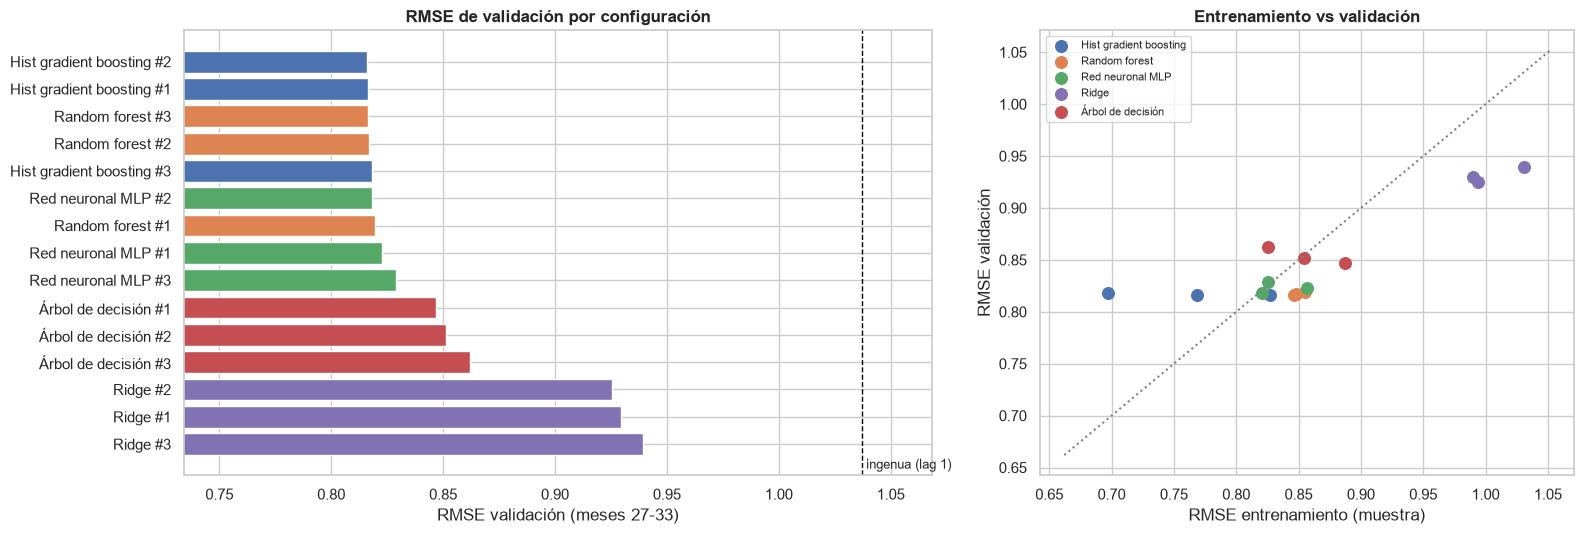

In [12]:
colores = dict(zip(torneo["modelo"].unique(), PALETA))
fig_comparacion, ejes = plt.subplots(1, 2, figsize=(16, 5.5),
                                     gridspec_kw={"width_ratios": [1.4, 1]})
orden = torneo.sort_values("rmse_val", ascending=False)
ejes[0].barh(orden["config"], orden["rmse_val"],
             color=orden["modelo"].map(colores))
ingenua = referencias.loc[2, "rmse_val"]
ejes[0].axvline(ingenua, color="black", ls="--", lw=1)
ejes[0].text(ingenua, -0.9, " ingenua (lag 1)", fontsize=9)
ejes[0].set_xlim(torneo["rmse_val"].min() * 0.9,
                 max(torneo["rmse_val"].max(), ingenua) * 1.03)
ejes[0].set_xlabel("RMSE validación (meses 27-33)")
ejes[0].set_title("RMSE de validación por configuración")

for modelo, grupo in torneo.groupby("modelo"):
    ejes[1].scatter(grupo["rmse_train"], grupo["rmse_val"], s=70,
                    color=colores[modelo], label=modelo)
limite = [torneo[["rmse_train", "rmse_val"]].min().min() * 0.95,
          torneo[["rmse_train", "rmse_val"]].max().max() * 1.02]
ejes[1].plot(limite, limite, color="gray", ls=":")
ejes[1].set_xlabel("RMSE entrenamiento (muestra)")
ejes[1].set_ylabel("RMSE validación")
ejes[1].set_title("Entrenamiento vs validación")
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.2 Error por mes de validación

El RMSE de la mejor configuración de cada familia en cada mes de validación. Muestra si el error es estable o si algún mes (por ejemplo, con lanzamientos grandes) es más difícil.

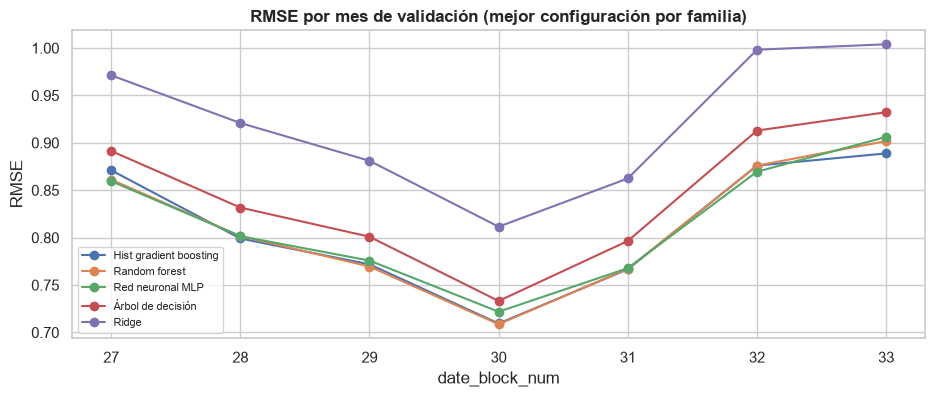

mes,27,28,29,30,31,32,33
Hist gradient boosting,0.8711,0.7991,0.7719,0.7094,0.7666,0.8760,0.8888
Random forest,0.8612,0.8017,0.7695,0.7086,0.7672,0.8759,0.9018
Red neuronal MLP,0.8596,0.8015,0.7758,0.7219,0.7677,0.8696,0.9062
Árbol de decisión,0.8914,0.8317,0.8010,0.7332,0.7965,0.9130,0.9323
Ridge,0.9712,0.9209,0.8811,0.8115,0.8624,0.9982,1.0040


In [13]:
meses_val = validacion["date_block_num"].to_numpy()
por_mes = {}
for _, fila in mejor_por_familia.iterrows():
    prediccion = recortar_prediccion(ajustados[fila["config"]]
                                     .predict(Xt_val))
    por_mes[fila["modelo"]] = (
        pd.DataFrame({"mes": meses_val, "real": y_val.to_numpy(),
                      "pred": prediccion})
        .groupby("mes")[["real", "pred"]]
        .apply(lambda g: root_mean_squared_error(g["real"], g["pred"])))
por_mes = pd.DataFrame(por_mes)
fig_meses, eje = plt.subplots(figsize=(11, 4))
for modelo in por_mes:
    eje.plot(por_mes.index, por_mes[modelo], marker="o",
             color=colores[modelo], label=modelo)
eje.set_xlabel("date_block_num")
eje.set_ylabel("RMSE")
eje.set_title("RMSE por mes de validación (mejor configuración por familia)")
eje.legend(fontsize=8)
plt.show()
por_mes.T

## 7. Modelo ganador

El ganador es la configuración con el menor RMSE de validación.

Ganador: Hist gradient boosting #2 | {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 15}
RMSE validación: 0.8159 (ingenua: 1.0373; mejora de 21.3%)


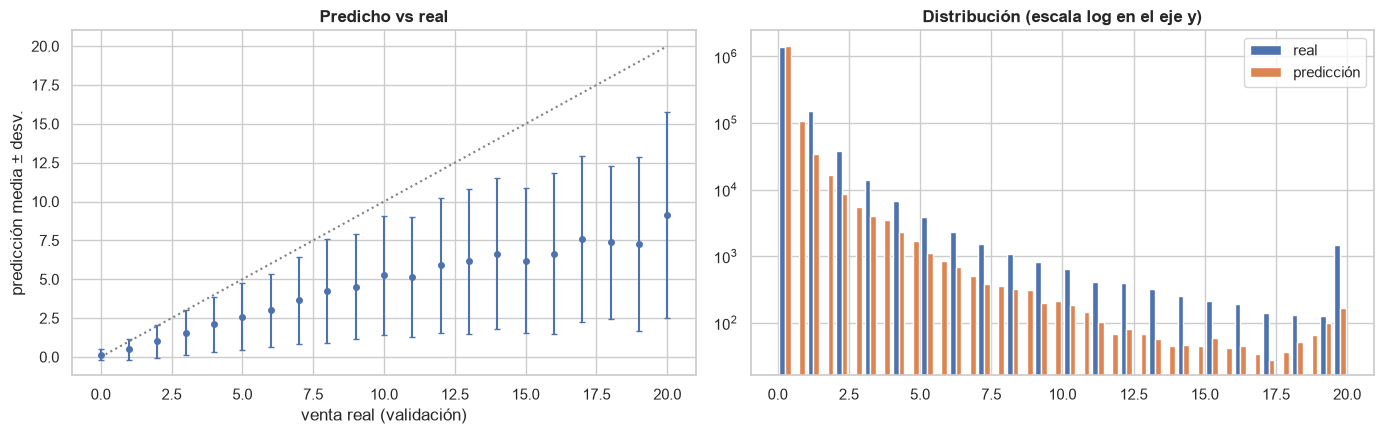

In [14]:
ganador = torneo.iloc[0]
modelo_ganador = ajustados[ganador["config"]]
print(f"Ganador: {ganador['config']} | {ganador['parametros']}")
print(f"RMSE validación: {ganador['rmse_val']:.4f} "
      f"(ingenua: {ingenua:.4f}; mejora de "
      f"{1 - ganador['rmse_val'] / ingenua:.1%})")

pred_val = recortar_prediccion(modelo_ganador.predict(Xt_val))
fig_pred_real, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
comparacion = pd.DataFrame({"real": y_val.to_numpy(), "pred": pred_val})
promedio = comparacion.groupby("real")["pred"].agg(["mean", "std"])
ejes[0].errorbar(promedio.index, promedio["mean"], yerr=promedio["std"],
                 fmt="o", color=PALETA[0], ms=4, capsize=2)
ejes[0].plot([0, 20], [0, 20], color="gray", ls=":")
ejes[0].set_xlabel("venta real (validación)")
ejes[0].set_ylabel("predicción media ± desv.")
ejes[0].set_title("Predicho vs real")
ejes[1].hist([comparacion["real"].clip(0.01), comparacion["pred"]],
             bins=40, range=(0, 20), label=["real", "predicción"],
             color=[PALETA[0], PALETA[1]], log=True)
ejes[1].set_title("Distribución (escala log en el eje y)")
ejes[1].legend()
plt.tight_layout()
plt.show()

### 7.1 Variables más importantes del ganador

Importancia por permutación en una submuestra de 200 mil filas de validación: cuánto sube el RMSE si se desordena cada variable. Muestra el peso de las variables exógenas de tienda y producto (codificadas por media del target) frente a los lags.

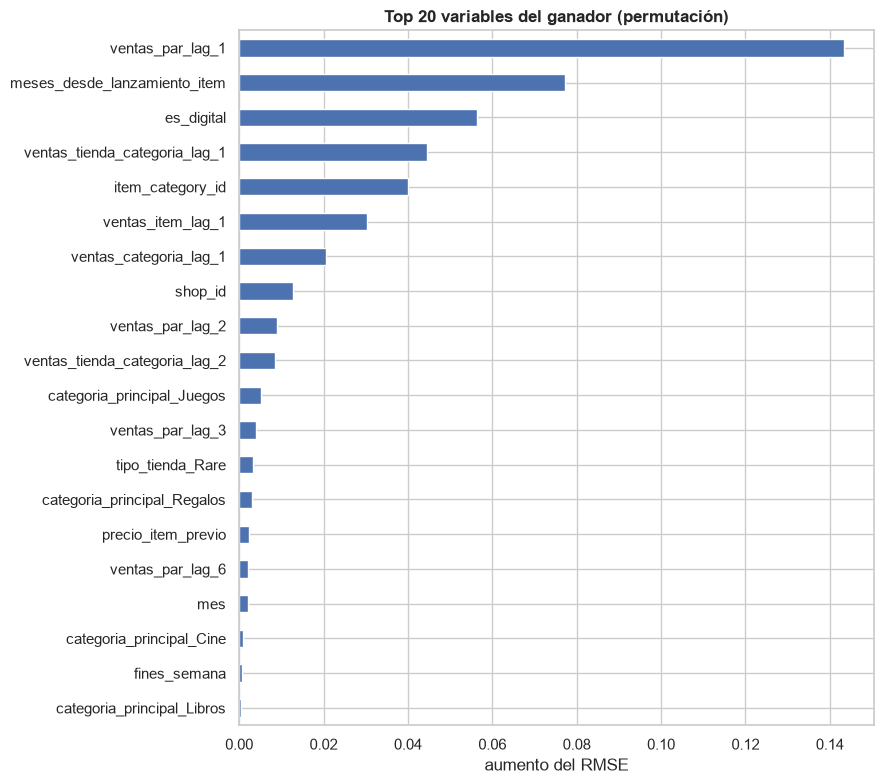

In [15]:
submuestra = Xt_val.sample(200_000, random_state=SEMILLA)
importancia = permutation_importance(
    modelo_ganador, submuestra, y_val.loc[submuestra.index],
    scoring="neg_root_mean_squared_error", n_repeats=3,
    random_state=SEMILLA, n_jobs=-1)
importancias = (pd.Series(importancia.importances_mean,
                          index=Xt_val.columns)
                .sort_values(ascending=False))
fig_importancia, eje = plt.subplots(figsize=(9, 8))
importancias.head(20)[::-1].plot.barh(color=PALETA[0], ax=eje)
eje.set_xlabel("aumento del RMSE")
eje.set_title("Top 20 variables del ganador (permutación)")
plt.tight_layout()
plt.show()

### 7.2 Lectura de los resultados

- **Ganador: Hist gradient boosting #2** (`learning_rate=0.1`, `max_iter=100`, `max_leaf_nodes=15`), con **RMSE de validación de 0.8159** (NRMSE de 0.041). Mejora 21.3 % a la predicción ingenua (1.037) y 25 % a predecir la media (1.085). Lo confirmó el usuario.
- **Empate técnico en la cima:** HistGB #1 (0.8163) y Random forest #3 (0.8163) quedan a 0.0004. Se prefiere HistGB por ser el más simple, por entrenar en 2 segundos (contra 16 del random forest) y por su `.pkl` pequeño.
- **Sobreajuste:** el ganador tiene brecha negativa (-1.4 %). Las configuraciones más complejas de HistGB entrenan mejor (0.70 en la #3), pero validan peor (0.818): sobreajustan. En varios modelos el RMSE de validación es menor que el de entrenamiento porque los meses 27-33 venden menos (media del target 0.26 contra 0.30), así que son más fáciles de predecir; no es una señal de error.
- **Por familia:** los ensambles de árboles y la MLP quedan en 0.816-0.818; el árbol simple en 0.847; Ridge en 0.925. Las relaciones son no lineales, y los ensambles las captan sin sobreajustar.
- **Por mes:** el error es más alto en los meses 27 y 32-33 (≈ 0.87-0.89) que en el 30 (0.71). Esos meses tienen más lanzamientos y ventas altas, más difíciles de anticipar con lags.
- **Variables exógenas:** además de los lags (sobre todo `ventas_par_lag_1`), el modelo usa mucho la antigüedad del producto, si es digital, la categoría (`item_category_id` codificada por media, ventas de la categoría y de tienda-categoría) y la tienda (`shop_id` codificada por media). La tienda y el producto entran como variables exógenas, como pide la consigna.

**Cuidado al interpretar:**

- El RMSE de validación del ganador es algo optimista, porque se usó para elegirlo entre 15 configuraciones.
- El ganador quedó en el extremo simple de su configuración. Una versión aún más simple podría rendir igual o mejor; queda como mejora futura, igual que dar más iteraciones a la MLP, que en dos configuraciones se detuvo en el máximo de 40 épocas sin converger del todo.

## 8. Pipeline completo

El pipeline completo une el pipeline de features **sin ajustar** (`clone`) y el modelo ganador **sin ajustar**, dentro de un `TransformedTargetRegressor` que recorta las predicciones a [0, 20] (`inverse_func=recortar_prediccion`). Recibe filas crudas `(date_block_num, shop_id, item_id)` y devuelve la predicción final.

```
TransformedTargetRegressor(inverse_func=recortar_prediccion)
└─ Pipeline
   ├─ features   pipeline_fe (mapear → lags → imputar → codificar → outliers → log → escalar)
   └─ modelo     ganador del torneo
```

1. **Verificación:** se ajusta con la misma muestra del torneo y se comprueba que da el mismo RMSE de validación.
2. **Reentrenamiento final:** se ajusta con **todos** los meses 12-33 (entrenamiento + validación). Es válido porque el modelo ya se eligió y test (mes 34) no se usa. Así el modelo aprende también de los meses más recientes, que son los más parecidos a noviembre de 2015.

In [16]:
def construir_pipeline_completo() -> TransformedTargetRegressor:
    """Pipeline sin ajustar: features + ganador + recorte a [0, 20]."""
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("features", clone(pipeline_fe)),
            ("modelo", clone(modelo_ganador)),
        ]),
        func=identidad, inverse_func=recortar_prediccion,
        check_inverse=False,
    )


inicio = time.time()
verificacion = construir_pipeline_completo().fit(X_muestra, y_muestra)
rmse_verificacion = root_mean_squared_error(y_val,
                                            verificacion.predict(X_val))
print(f"RMSE validación del pipeline completo: {rmse_verificacion:.4f} "
      f"(torneo: {ganador['rmse_val']:.4f}) | "
      f"{time.time() - inicio:.0f} s")
assert np.isclose(rmse_verificacion, ganador["rmse_val"], atol=1e-6)

RMSE validación del pipeline completo: 0.8159 (torneo: 0.8159) | 15 s


In [17]:
inicio = time.time()
pipeline_completo = construir_pipeline_completo().fit(
    malla[ENTRADA], malla[TARGET])
print(f"Reentrenado con los meses 12-33: {len(malla):,} filas en "
      f"{time.time() - inicio:.0f} s")

ruta_completo = MODELS_DIR / "pipeline_completo.pkl"
joblib.dump(pipeline_completo, ruta_completo, compress=3)
print(f"{ruta_completo.name}: {ruta_completo.stat().st_size / 1e6:.1f} MB")

recargado = joblib.load(ruta_completo)
assert np.allclose(recargado.predict(X_val.head(1_000)),
                   pipeline_completo.predict(X_val.head(1_000)))
print("El pipeline recargado predice igual.")

Reentrenado con los meses 12-33: 6,425,094 filas en 54 s
pipeline_completo.pkl: 28.6 MB
El pipeline recargado predice igual.
